In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [2]:
X,y,c= make_blobs(n_samples= 500, cluster_std= 0.8, centers= 4, n_features= 2, return_centers= True)

df= pd.DataFrame({
    "x1": X[:,0],
    "x2": X[:,1]
})

df_centers= pd.DataFrame({
    "x1": c[:,0],
    "x2": c[:,1],
})

In [3]:
X_m, y_m= make_moons(n_samples=250, noise= 0.05, random_state=42)

df_moons= pd.DataFrame(
    {
        "x1": X_m[:,0],
        "x2": X_m[:,1]
    }
)

<Axes: xlabel='x1', ylabel='x2'>

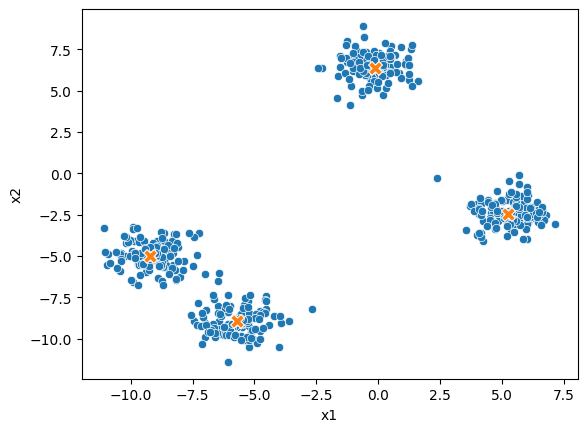

In [4]:
sns.scatterplot(data= df, x= "x1", y= "x2")
sns.scatterplot(data= df_centers, x= "x1", y= "x2", marker= "X", s=100)

<Axes: xlabel='x1', ylabel='x2'>

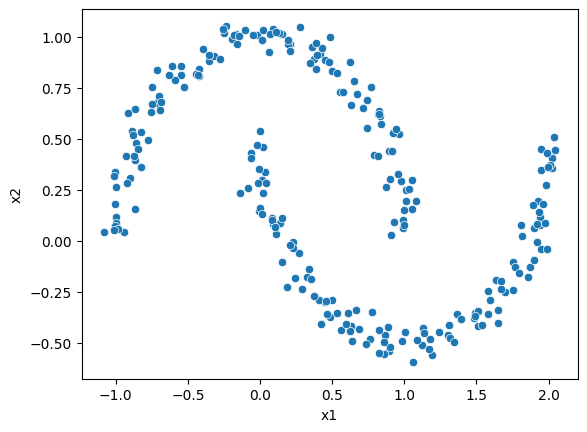

In [5]:
sns.scatterplot(data= df_moons, x="x1", y="x2")

<Axes: xlabel='x1', ylabel='x2'>

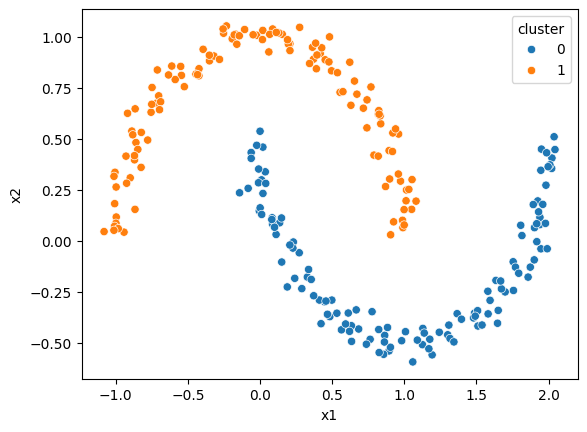

In [6]:
dbscan_cluster= DBSCAN(eps= 0.3, min_samples=3)
y_m_predict= dbscan_cluster.fit_predict(X_m)
df_moons["cluster"]= y_m_predict

sns.scatterplot(data= df_moons, x="x1", y="x2", hue= "cluster")

<Axes: xlabel='x1', ylabel='x2'>

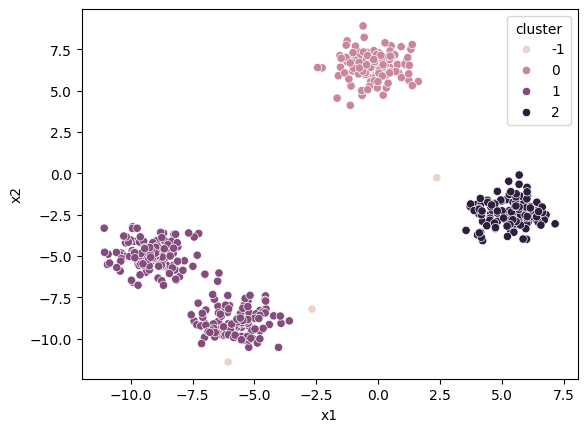

In [8]:
dbscan= DBSCAN(eps= 1, min_samples=4)
y_predict= dbscan.fit_predict(X)
df["cluster"]= y_predict

sns.scatterplot(data= df, x= "x1", y= "x2", hue= "cluster")

ENCONTRAR HIPERPARAMETROS

In [46]:
from sklearn.neighbors import NearestNeighbors

neighbors= NearestNeighbors(n_neighbors=4) #Un truco sumar las dimensiones y multiplicar por 2. Es decir, 2 ejes (x,y)*2 = 4
neighbors_fit= neighbors.fit(X)
distances, incides= neighbors_fit.kneighbors(X)

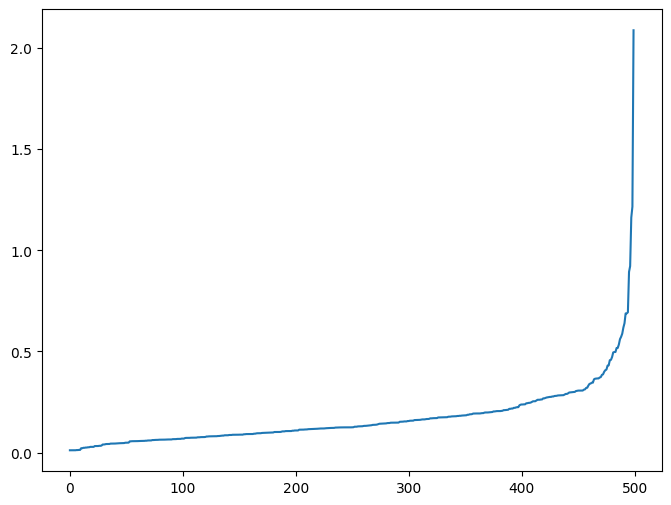

In [47]:
plt.figure(figsize=(8,6))
distances= np.sort(distances, axis=0)
distances= distances[:,1]
plt.plot(distances)

#Con esta grafica "De rodilla" se toman los valores cercanos a la "rodilla". En este caso, voy a tomar
#los valores entre 0.2 a 0.7

In [48]:
eps_values= np.arange(0.2, 0.7, 0.1)
min_sample= np.arange(2,10)

In [53]:
from itertools import product

dbscan_params= list(product(eps_values, min_sample)) 
sil_score= [] 

for i in dbscan_params:
    y_pred= DBSCAN(eps= i[0], min_samples= i[1]).fit_predict(X)
    sil_score.append(silhouette_score(X, y_pred))

<Axes: xlabel='Eps', ylabel='Min_Samples'>

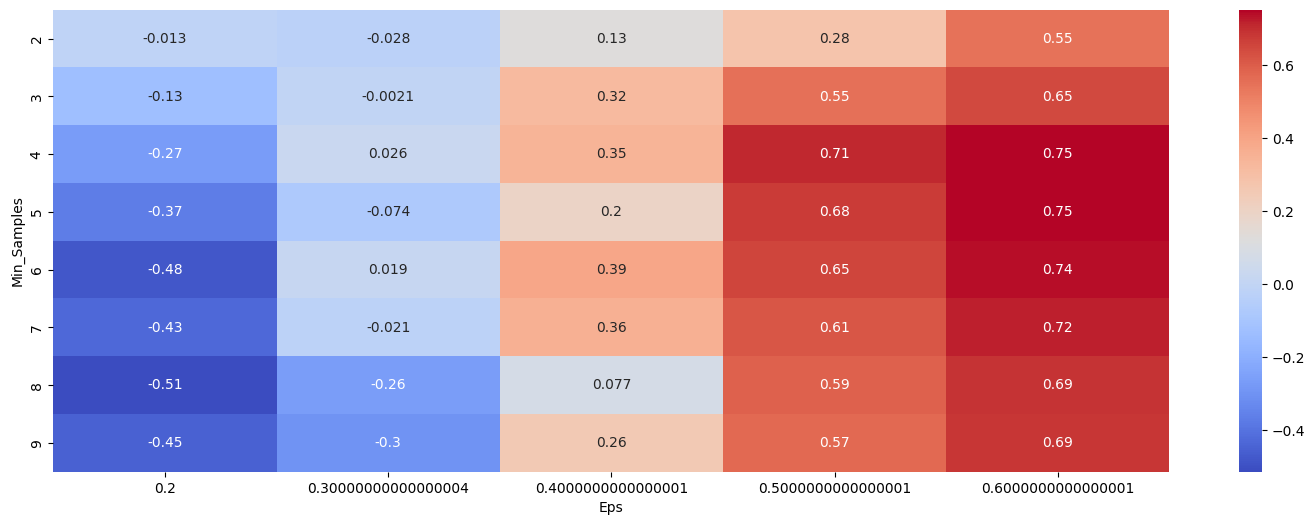

In [66]:
df_params_tunning= pd.DataFrame(dbscan_params, columns= ["Eps", "Min_Samples"])
df_params_tunning["sil_scores"]= sil_score   

pivot_data= pd.pivot_table(df_params_tunning, values= "sil_scores", index= "Min_Samples", columns= "Eps") #Crear una tabla dinamica

plt.figure(figsize= (18,6))
sns.heatmap(pivot_data, annot= True, annot_kws= {"size": 10} , cmap="coolwarm")

EVALUAR EL MODELO

<Axes: xlabel='x1', ylabel='x2'>

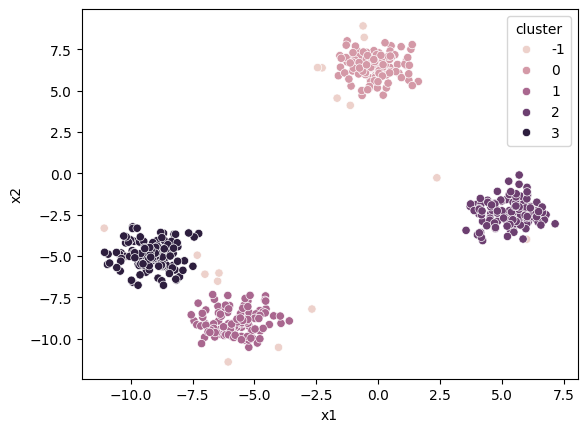

In [68]:
dbscan_cluster= DBSCAN(eps= 0.6, min_samples=4)
y_predict= dbscan_cluster.fit_predict(X)
df["cluster"]= y_predict

sns.scatterplot(data= df, x= "x1", y= "x2", hue= "cluster")

For n_clusters = 5 The average silhouette_score is : 0.7523925706550795


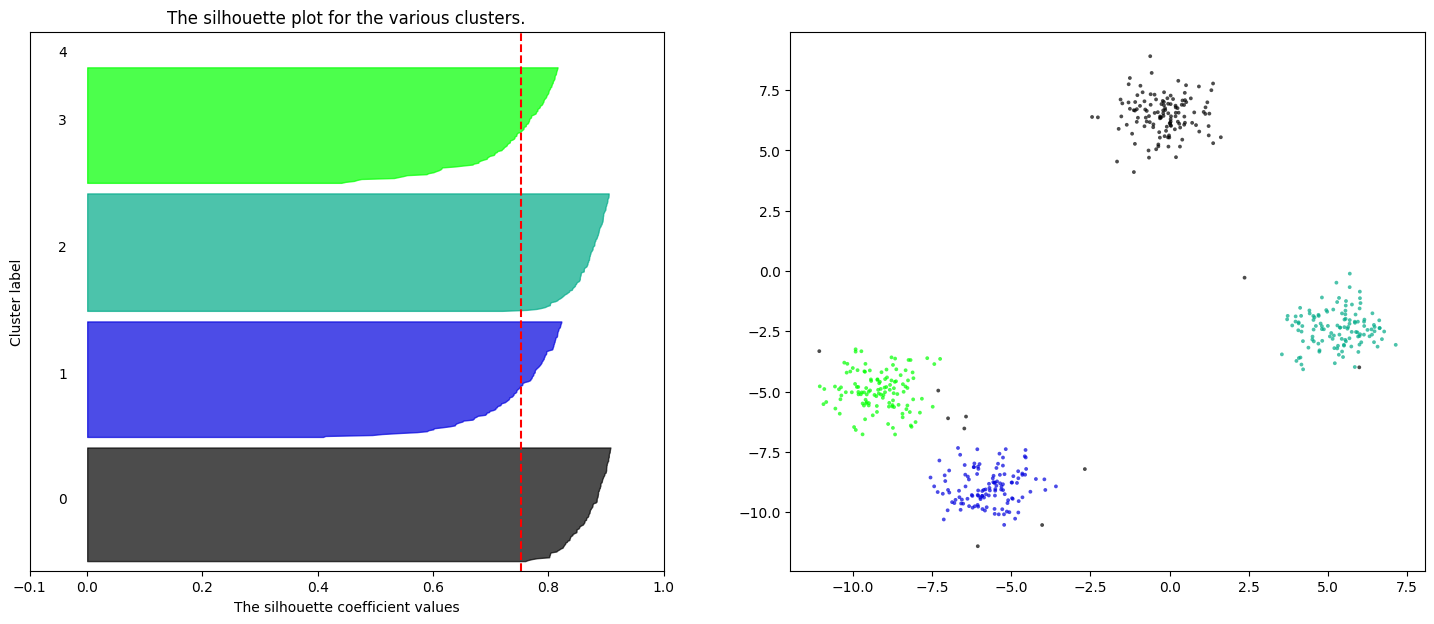

In [69]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_samples, silhouette_score


# Create a subplot with 1 row and 2 columns
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.set_size_inches(18, 7)
# The 1st subplot is the silhouette plot
# The silhouette coefficient can range from -1, 1 but in this example all
# lie within [-0.1, 1]
ax1.set_xlim([-0.1, 1])
# The (n_clusters+1)*10 is for inserting blank space between silhouette
# plots of individual clusters, to demarcate them clearly.

clusterer = DBSCAN(eps= 0.6, min_samples=4)
cluster_labels = clusterer.fit_predict(X)
n_clusters = len(np.unique(cluster_labels))

ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])
# Initialize the clusterer with n_clusters value and a random generator
# seed of 10 for reproducibility.

# The silhouette_score gives the average value for all the samples.
# This gives a perspective into the density and separation of the formed
# clusters
silhouette_avg = silhouette_score(X, cluster_labels)
print(
    "For n_clusters =",
    n_clusters,
    "The average silhouette_score is :",
    silhouette_avg,
)
# Compute the silhouette scores for each sample
sample_silhouette_values = silhouette_samples(X, cluster_labels)
y_lower = 10
for i in range(n_clusters):
    # Aggregate the silhouette scores for samples belonging to
    # cluster i, and sort them
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i
    color = cm.nipy_spectral(float(i) / n_clusters)
    ax1.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_silhouette_values,
        facecolor=color,
        edgecolor=color,
        alpha=0.7,
    )
    # Label the silhouette plots with their cluster numbers at the middle
    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    # Compute the new y_lower for next plot
    y_lower = y_upper + 10  # 10 for the 0 samples
ax1.set_title("The silhouette plot for the various clusters.")
ax1.set_xlabel("The silhouette coefficient values")
ax1.set_ylabel("Cluster label")
# The vertical line for average silhouette score of all the values
ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
ax1.set_yticks([])  # Clear the yaxis labels / ticks
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
# 2nd Plot showing the actual clusters formed
colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
ax2.scatter(
    X[:, 0], X[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
)


plt.show()